In [2]:
import os
import xarray as xr
import socket
import subprocess
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
import cupy as cp
import cucim
from cucim.skimage.morphology import ball as GPUball
from scipy import ndimage
import cupyx.scipy.ndimage as GPUndimage
import cucim.skimage.morphology as cumorph
import skimage
from joblib import Parallel, delayed
import pickle

#paths
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
    
elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = os.path.join(toppath, 'processing')
    temppath = '/mnt/SSD_2TB_nvme0n1/Robert/tmp/'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
else:
    print('host '+host+' currently not supported')

charge_path = os.path.join(toppath, 'processing', 'charge_dict.p')
charge_dict = pickle.load(open(charge_path, 'rb'))

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [2]:
# for i in range(5):
#     with cp.cuda.Device(i):
#         mempool = cp.get_default_memory_pool()
#         mempool.free_all_blocks()

In [3]:
sample = '6'
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [4]:
seg_data = xr.open_dataset(segpath)

In [5]:
seg_data

<xarray.Dataset>
Dimensions:    (x: 750, y: 340, z: 1916, timestep: 84, feature: 106)
Coordinates:
  * x          (x) int64 0 1 2 3 4 5 6 7 8 ... 742 743 744 745 746 747 748 749
  * y          (y) int64 0 1 2 3 4 5 6 7 8 ... 332 333 334 335 336 337 338 339
  * z          (z) int64 0 1 2 3 4 5 6 7 ... 1909 1910 1911 1912 1913 1914 1915
  * timestep   (timestep) int64 0 1 2 3 4 5 6 7 8 ... 75 76 77 78 79 80 81 82 83
  * feature    (feature) <U27 'Gaussian_4D_Blur_0.0' ... 'full_temp_min_Gauss...
Data variables:
    segmented  (x, y, z, timestep) uint8 ...
    t_utc      (timestep) float64 ...
    time       (timestep) float64 ...
Attributes: (12/28)
    name:                                              6
    voxel size:                                        2.75 um
    voxel:                                             2.75e-06
    post rotation cropping coordinates [a:b,c:d,e:f]:  [  10  879   70  770  ...
    rotation angle 1:                                  2
    rotation angle 2:                                  2
    ...                                                ...
    githash_registration:                              612e92b28895745f6b422c...
    git_sha_filtering:                                 2f2a4cd
    githash_filtering:                                 2f2a4cd95073ec055855d7...
    05_ML_cropping:                                    [105 855  30 370  50 -50]
    pytrain_git:                                       5ad5465
    05_coely_gitsha:                                   7459646

In [6]:
test = seg_data['segmented'].sel(timestep = 20)

In [7]:
# water  = test == 2

In [8]:
fiber = test == 0

In [9]:
im = fiber.sel(y =250)

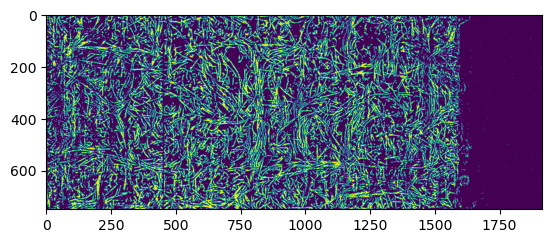

In [10]:
plt.imshow(im)

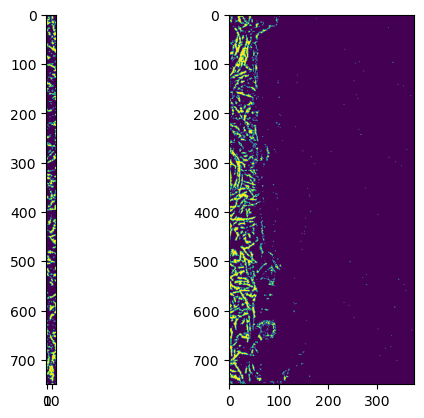

In [11]:
a = 20
b = 1540
fig, axs = plt.subplots(1,2)
axs[0].imshow(im[:,:a])
axs[1].imshow(im[:,b:])

In [22]:
crops = {
'1': (180,-310),
'4': (280,-250),
'3II': (140,1620),
'3III': (40,1370),
'5': (160, 1580),
'6': (20, 1540)
}

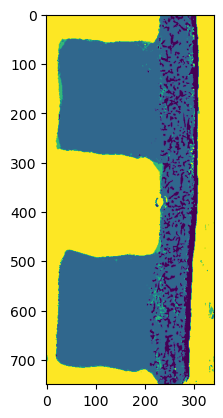

In [23]:
plt.imshow(test[:,:,650])

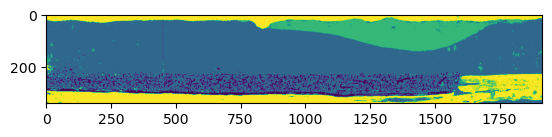

In [15]:
plt.imshow(test[110,:,:])

In [24]:
def get_GDL_mask(segim):
    fiber = segim == 0
    fibercp = cp.array(fiber)
    fibercp = GPUndimage.binary_opening(fibercp, structure=GPUball(1))
    dst = ndimage.distance_transform_cdt(~cp.asnumpy(fibercp))
    fibercp = cp.array(dst<3)
    labels = cucim.skimage.measure.label(fibercp)
    fibercp = labels == cp.argmax(cp.bincount(labels[fibercp]))
    del labels
    fibercp = GPUndimage.binary_erosion(fibercp, structure=GPUball(3))
    fibercp = GPUndimage.binary_dilation(fibercp, structure=GPUball(6))
    fibercp = GPUndimage.binary_fill_holes(fibercp)
    fibercp = GPUndimage.binary_erosion(fibercp, structure=GPUball(3))
    mask = cp.asnumpy(fibercp)
    del fibercp
    mempool = cp.get_default_memory_pool()
    mempool.free_all_blocks()
    return mask

In [25]:
def get_channel_masks(segim, mask, a, b):
    back = segim == 3
    FFcp = cp.array(back)
    FFcp = GPUndimage.binary_opening(FFcp, GPUball(4))
    
    FFcp = FFcp + cp.array(mask)
    FFcp[:5,:] = True
    FFcp[-5:,:] = True
    FFcp[:,:5] = True
    FFcp[:,-5:] = True
    FFcp = GPUndimage.binary_closing(FFcp, GPUball(4))
    FFcp[:5,:] = True
    FFcp[-5:,:] = True
    FFcp[:,:5] = True
    FFcp[:,-5:] = True
    cut = int(FFcp.shape[0]/2)
    FFcp[cut,:,:] = True
    FFlabels = cucim.skimage.measure.label(~FFcp[:,:,a:b], connectivity=2)
    FFcp[...] = False
    id, count = cp.unique(FFlabels, return_counts = True)
    id1,id2 = id[cp.argsort(count)][-3:-1]
    FFcp[:,:,a:b] = FFlabels==int(id1)

    channel1 = cp.asnumpy(FFcp)
    FFcp[...] = False
    FFcp[:,:,a:b] = FFlabels==int(id2)
    channel2 = cp.asnumpy(FFcp)

    del FFcp, FFlabels
    mempool = cp.get_default_memory_pool()
    mempool.free_all_blocks()

    # check which channel is on top and assign accordingly
    if np.argmax(channel1[:,:,650].sum(axis=1))>np.argmax(channel2[:,:,650].sum(axis=1)):
        return channel1, channel2
    else:
        return channel2, channel1
    

In [26]:
def get_channel_GDL_masks(channel1, channel2,a,b):
    GDLchannel1 = channel1.sum(axis=1)>100
    GDLchannel2 = channel2.sum(axis=1)>100
    GDLland = ~np.bitwise_or(GDLchannel1, GDLchannel2)
    GDLland[:,:a] = False
    GDLland[:,b:] = False
    labels = skimage.measure.label(GDLland)
    GDLrib = labels == np.argmax(np.bincount(labels[GDLland]))
    
    return GDLchannel1, GDLchannel2, GDLland, GDLrib

In [27]:
def get_timestep_mask(ts, seg_data, a,b):
    test = seg_data['segmented'].sel(timestep = ts)

    gpu_id = ts%5
    # while cp.cuda.Device(gpu_id).mem_info[0]<8E9:
    #     time.sleep(1)
    
    with cp.cuda.Device(gpu_id):
        mask = get_GDL_mask(test)
        channel1, channel2 = get_channel_masks(test, mask, a, b)
        GDLchannel1, GDLchannel2, GDLland, GDLrib = get_channel_GDL_masks(channel1, channel2,a,b)
        mask = mask.astype(np.uint8)

    segments = np.zeros(mask.shape, dtype = np.uint8)
    segments[channel1] = 1
    segments[channel2] = 2
    segments = segments + GDLchannel1[:,None,:].astype(np.uint8)*3*mask
    segments = segments + GDLchannel2[:,None,:].astype(np.uint8)*4*mask
    segments = segments + GDLland[:,None,:].astype(np.uint8)*6*mask
    segments = segments - GDLrib[:,None,:].astype(np.uint8)*1*mask
    

    return segments, mask
    
    

In [28]:
def all_segments(seg_data, a, b,):
    timesteps = seg_data['timestep'].data
    results = Parallel(n_jobs = 5, temp_folder=temppath)(delayed(get_timestep_mask)(ts, seg_data, a,b) for ts in timesteps)
    segments = [result[0] for result in results]
    mask = [result[0] for result in results]
    segments = np.stack(segments, axis=-1).astype(np.uint8)
    mask = np.stack(mask, axis=-1).astype(np.uint8)
    return segments, mask

In [29]:
# mask = get_GDL_mask(test)

In [30]:
a, b = crops[sample]
# channel1, channel2 = get_channel_masks(test, mask, a, b)

In [31]:
ts = 0
segments, mask = get_timestep_mask(ts, seg_data, a,b)

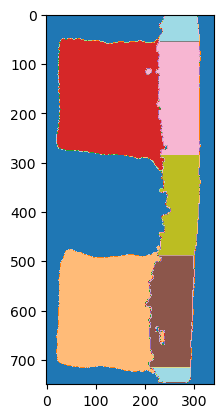

In [36]:
plt.imshow(segments[:,:,650], cmap='tab20')

In [33]:
segments_0 = segments.copy()

In [26]:
segments, mask = all_segments(seg_data, a,b)


/mpc/homes/fische_r/miniconda3/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [34]:
plt.imshow(segments[:,:,650,20], cmap='tab20',vmin=0,vmax=6)

IndexError: too many indices for array: array is 3-dimensional, but 4 were indexed

In [16]:
raw_data = xr.open_dataset(os.path.join(toppathSSD, '04_lowpass_filtered_4D', '04_'+sample+'_lowpass_filteres_4D.nc'))

In [17]:
import json
jsonpath = os.path.join(training_path, 'cathode_cropping_and_aligning.json')
crop_dict = json.load(open(jsonpath, 'r'))

(a,b,c,d) = crop_dict[sample]
(e,f) = (50,-50)

In [18]:
raw_test = raw_data['image_data'][a:b,c:d,e:f,20].data


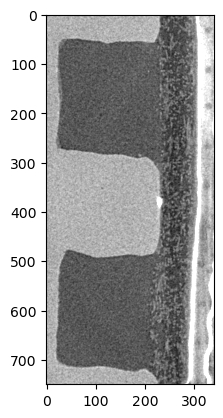

In [19]:
plt.imshow(raw_test[:,:,650], cmap='gray', vmin=10000, vmax=14000)

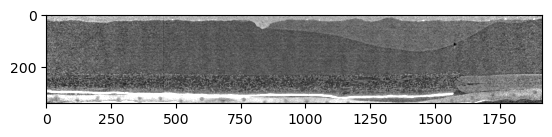

In [20]:
plt.imshow(raw_test[110,:,:], cmap='gray', vmin=10000, vmax=14000)

In [28]:
# ROIdata = xr.load_dataset(ROIpath)

In [29]:
# segments = ROIdata['ROI'].data.astype(np.uint8)
# mask = ROIdata['GDL'].data.astype(np.uint8)

In [30]:
segments.dtype

dtype('uint8')

In [31]:
shp = segments.shape
ROIdata = xr.Dataset({'ROI': (['x','y','z','timestep'], segments),
                      'GDL': (['x','y','z','timestep'], mask),
                     't_utc': ('timestep',seg_data['t_utc'].data),
                     'time': ('timestep',seg_data['time'].data)},
                               coords = {'x': np.arange(shp[0]),
                               'y': np.arange(shp[1]),
                               'z': np.arange(shp[2]),
                               'timestep': np.arange(shp[3])
                               })
ROIdata.attrs = seg_data.attrs
ROIdata.attrs['ROI values'] = [1,2,3,4,5,6]
ROIdata.attrs['crops'] = [a,b]
ROIdata.attrs['ROI'] = ['channel1', 'channel2', 'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']

In [32]:
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
# ROIpath = os.path.join(toppath,'processing', '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')

In [33]:
ROIpath

'/mnt/SSD/fische_r/COELY/05_water_GDL_ML/6/6_ROI_segments.nc'

In [34]:
ROIdata.to_netcdf(ROIpath)

## Analysis per sample

In [57]:
def get_profiles(segdata, ROIdata):

    mask = ROIdata['ROI']>0    
    water = seg_data['segmented'] == 2
    gas = seg_data['segmented'] == 1
    
    water = water*mask
    gas = gas*mask

    waterprof_xz = water.sum(dim='z')
    gasprof_xz = gas.sum(dim='z')
    satprof_xz = waterprof_xz/(waterprof_xz +  gasprof_xz)

    waterprof_x = waterprof_xz.sum(dim='x')
    gasprof_x = gasprof_xz.sum(dim='x')
    satprof_x = waterprof_x/(waterprof_x +  gasprof_x)

    profdict = {'waterprof_xz': waterprof_xz, 'gasprof_xz': gasprof_xz, 'satprof_xz': satprof_xz, 'waterprof_x': waterprof_x, 'gasprof_x': gasprof_x, 'satprof_x': satprof_x, 'shape_raw': water.shape, 'water': water, 'gas': gas}
    return profdict

def plot_profiles(profdict, time, vmin=0, vmax=100, timesteps = [0,20,40,60], type='saturation'):
    timesteps_all = profdict['satprof_xz']['timestep']
    shp_raw = profdict['shape_raw'] #shape not considering the cropping, irrelevant for 1D saturation profiles, but to be considered for water content
    
    # 2D profiles
    norm = Normalize(vmin=vmin, vmax=vmax)
    cmap = cm.viridis
    fig, axs = plt.subplots(1,4, figsize=(15,7))

    if  type=='saturation':
        prof = profdict['satprof_xz']*100
        prof1D = profdict['satprof_x']*100
        label = 'saturation [%]'
    elif type == 'water content':
        prof = profdict['waterprof_xz']
        prof1D = profdict['waterprof_x']
        label = 'water content [px]'

    
    for i in range(4):
        ts =  timesteps[i]
        axs[i].imshow(prof.sel(timestep=ts), norm=norm)
        axs[i].set_title(f'{(time[ts]/60):.1f}'+' min')

    for ax in axs:
        ax.axis('off')
        scalebar = AnchoredSizeBar(ax.transData,
                                   250/2.75, '500 $\mu m$', 'upper right', 
                                   pad=0.25,
                                   color='white',
                                   frameon=False,
                                   size_vertical=8
                                   )
        ax.add_artist(scalebar)
    
        divider = make_axes_locatable(ax)
        cax = divider.append_axes('right', size='5%', pad=0.05)    
        fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),  cax=cax,  label=label) 

    # 1D profiles
    norm = Normalize(vmin=time[0]/60, vmax=time[-1]/60)
    cmap = cm.magma
    x = np.arange(shp_raw[1])*2.75
    fig, ax = plt.subplots()
    for ts in timesteps_all:
        ax.plot(x, prof1D.sel(timestep=ts), color=cmap(norm(time[ts]/60)))
    divider = make_axes_locatable(ax)
    cax = divider.append_axes('right', size='5%', pad=0.05)    
    fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),  cax=cax,  label='time [min]')  
    ax.set_ylabel(label)
    ax.set_xlabel('x [$\mu$m] (FF to left, CL to the right)')


In [80]:
def water_per_ROI(ROIdata, water,gas, roi):
    ROI = ROIdata['ROI']==roi
    ROIvol = ROI.sum(dim=('x','y','z'))
    waterROI = water*ROI
    gasROI = gas*ROI
    WATvol = waterROI.sum(dim=('x','y','z'))
    GASvol = gasROI.sum(dim=('x','y','z'))
    return WATvol, ROIvol, GASvol

def ROI_dynamics(ROIdata, profdict):
    ROIvals = ROIdata.attrs['ROI values'] 
    ROInames = ROIdata.attrs['ROI']
    water = profdict['water']
    gas = profdict['gas']
    roi_dyn_dict = {}
    for (roi, roiname) in zip(ROIvals, ROInames):
        if roiname == 'GDL_all_land':
           roiname = 'GDL_other_land' 
        WATvol, ROIvol, GASvol = water_per_ROI(ROIdata, water,gas, roi)
        SAT = WATvol/(WATvol + GASvol)
        roi_dyn_dict[roiname] = {'WATvol': WATvol, 'ROIvol': ROIvol, 'GASvol': GASvol, 'SAT': SAT}
    return roi_dyn_dict



def plot_roi_dynamic(roi_dyn_dict, time, rois = ['channel1', 'channel2', 'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land'], type='saturation', plot_sum=True, colors = None):
    allrois = ['channel1', 'channel2', 'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']
    
    sumwat = []
    fig, ax = plt.subplots()

    
    for i in range(len(allrois)):
        roi = allrois[i]
        if roi in rois:
            print(roi)
            if  type=='saturation':
                data = roi_dyn_dict[roi]['SAT']*100
                label = 'saturation [%]'
            elif type == 'water content':
                data = roi_dyn_dict[roi]['WATvol']
                label = 'water content [px]'
                sumwat.append(data)
            if not colors:
                ax.plot(timeCT/60,data,label=roi, marker='.', color=cm.tab10(i))
            else:
                ax.plot(timeCT/60,data,label=roi, marker='.', color=colors[i])
                
    if type == 'water content' and plot_sum:
        sumwat = np.stack(sumwat)
        sumwat = sumwat.sum(axis=0)
        ax.plot(timeCT/60,sumwat,label='sum', marker='.', color='k', linestyle='--')
    
    plt.xlabel('time [min]')
    plt.ylabel(label)
    plt.legend()

def plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC,I,V, rois = ['channel1', 'channel2', 'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land'], type='saturation', op = 'voltage', plot_sum=True):
    allrois = ['channel1', 'channel2', 'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']
    if  op == 'voltage':
        ecdata = V
        eclabel = op+' [V]'
    elif op == 'current':
        ecdata = I
        eclabel = op+'density [$mA/cm^2$]'
    else:
        op = 'voltage'
        ecdata = V
        eclabel = op+' [V]'
    sumwat = []
    fig, ax = plt.subplots()
    for i in range(len(allrois)):
        roi = allrois[i]
        if roi in rois:
            print(roi)
            if  type=='saturation':
                data = roi_dyn_dict[roi]['SAT']*100
                label = 'saturation [%]'
            elif type == 'water content':
                data = roi_dyn_dict[roi]['WATvol']
                label = 'water content [px]'
                sumwat.append(data)
            ax.plot(timeCT/60,data,label=roi, marker='.', color=cm.tab10(i))

    if type == 'water content' and plot_sum:
        sumwat = np.stack(sumwat)
        sumwat = sumwat.sum(axis=0)
        ax.plot(timeCT/60,sumwat,label='sum', marker='.', color='k', linestyle='--')
        
    ax2 = ax.twinx()
    ax2.plot(timeEC[::20]/60, ecdata[::20], 'k', label=op)

    ax.set_xlabel('time [min]')
    ax.set_ylabel(label)
    ax2.set_ylabel(eclabel)
    ax.legend(loc = 'upper left')
    ax2.legend(loc = 'upper right')
    

In [59]:
test = np.array([1,2,3,4])
test2 = np.stack([test,test,test])

In [5]:
test2.sum(axis=0)

array([ 3,  6,  9, 12])

## Sample 1 (reference without current)

In [32]:
sample = '1'
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [34]:
seg_data = xr.open_dataset(segpath)
ROIdata  = xr.open_dataset(ROIpath)
if sample == '1':
    t0 = ROIdata['t_utc'][0]
else:
    t0 = charge_dict[sample]['t0']
    timeEC = charge_dict[sample]['time']
    I = -charge_dict[sample]['I']*10 #current density [mA/cm2]
    V = -charge_dict[sample]['E'] #voltage

timeCT = ROIdata['t_utc']-t0





In [35]:
profdict = get_profiles(seg_data, ROIdata )

In [36]:
roi_dyn_dict = ROI_dynamics(ROIdata, profdict)

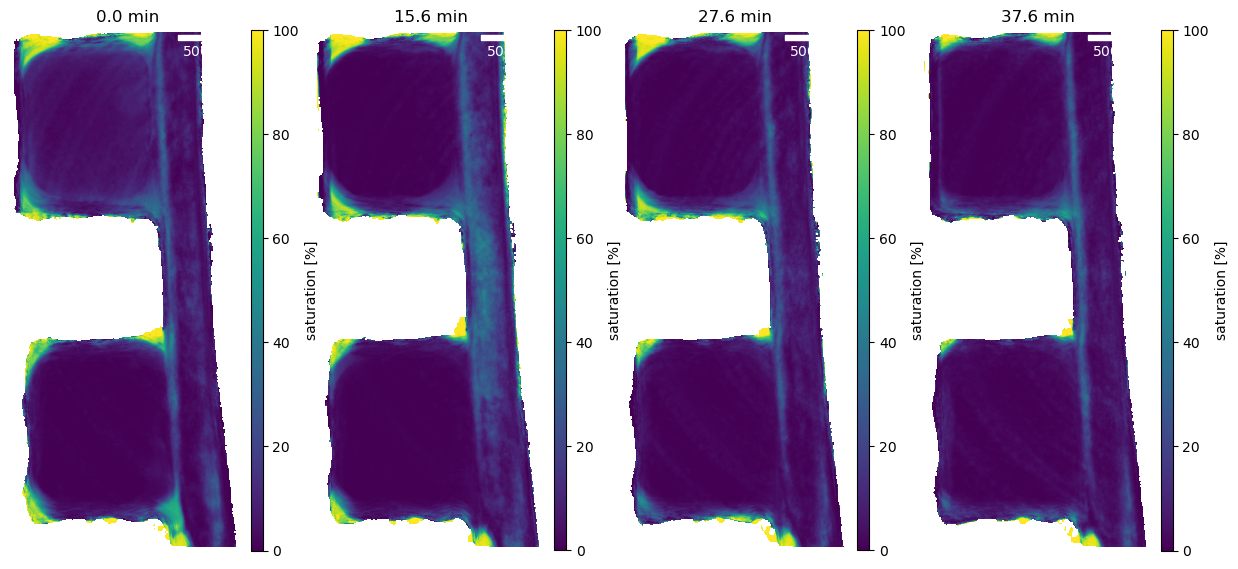

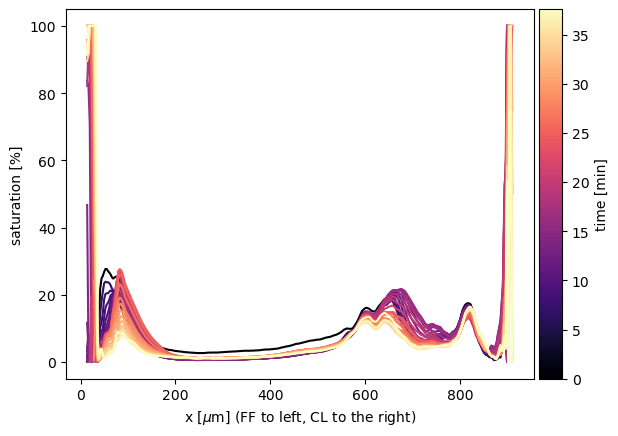

In [39]:
plot_profiles(profdict, timeCT, timesteps = [0,10,20,30])

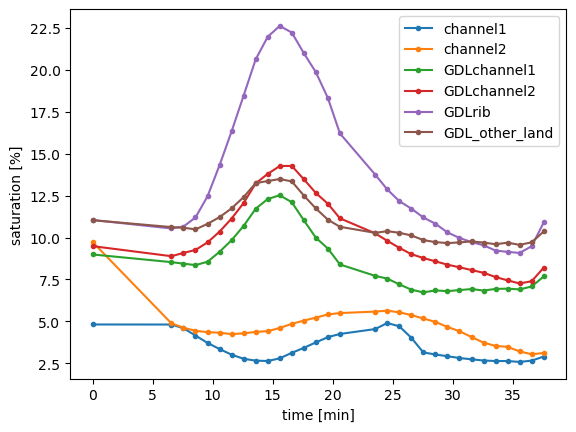

In [40]:
plot_roi_dynamic(roi_dyn_dict, timeCT)

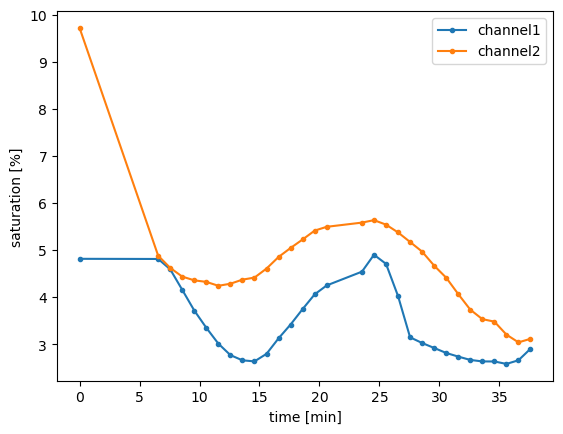

In [41]:
plot_roi_dynamic(roi_dyn_dict, timeCT, rois = ['channel1', 'channel2'])

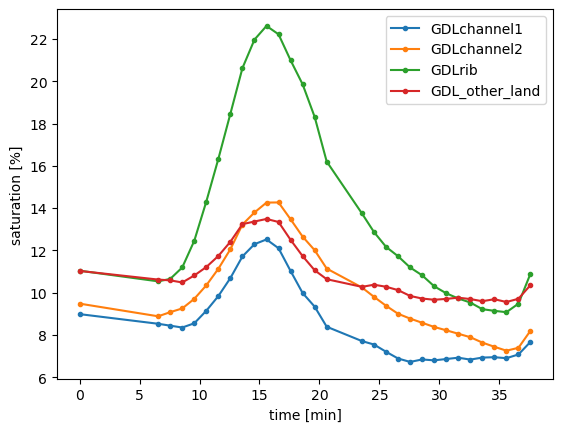

In [42]:
plot_roi_dynamic(roi_dyn_dict, timeCT, rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land'])

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


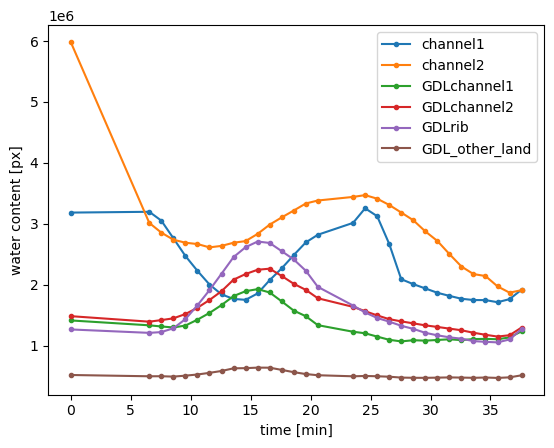

In [54]:
plot_roi_dynamic(roi_dyn_dict, timeCT, type='water content', plot_sum=False)

channel1
channel2


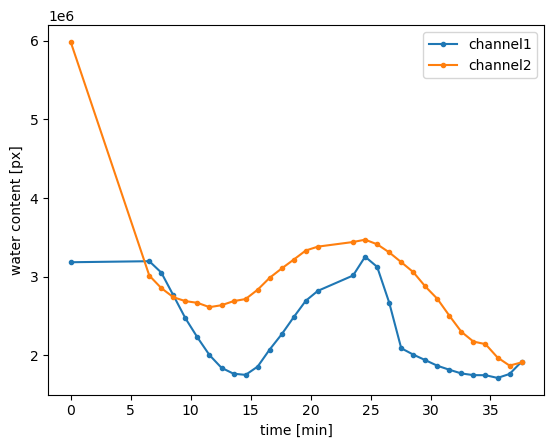

In [55]:
plot_roi_dynamic(roi_dyn_dict, timeCT, rois = ['channel1', 'channel2'], type='water content', plot_sum=False)

GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


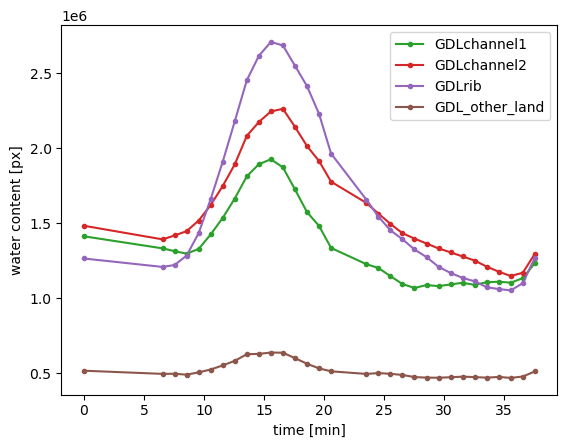

In [56]:
plot_roi_dynamic(roi_dyn_dict, timeCT, rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land'], type='water content', plot_sum=False)

## Sample 4

In [60]:
sample = '4'
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [61]:
seg_data = xr.open_dataset(segpath)
ROIdata  = xr.open_dataset(ROIpath)
if sample == '1':
    t0 = ROIdata['t_utc'][0]
else:
    t0 = charge_dict[sample]['t0']

timeCT = ROIdata['t_utc']-t0
timeEC = charge_dict[sample]['time']

I = -charge_dict[sample]['I']*10 #current density [mA/cm2]
V = -charge_dict[sample]['E'] #voltage


In [62]:
profdict = get_profiles(seg_data, ROIdata )

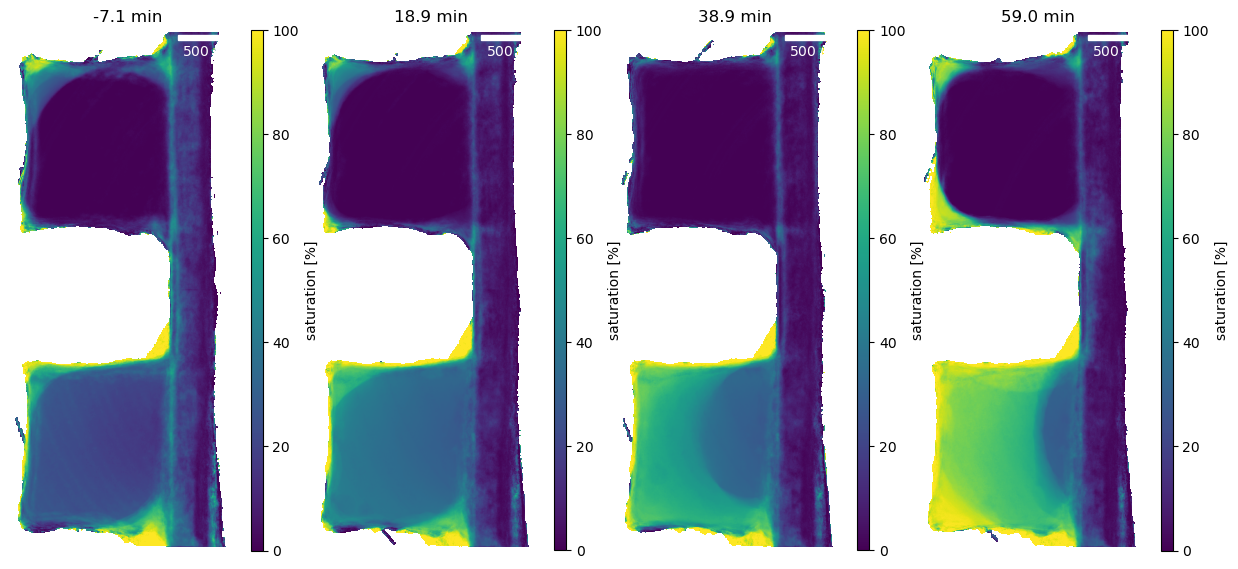

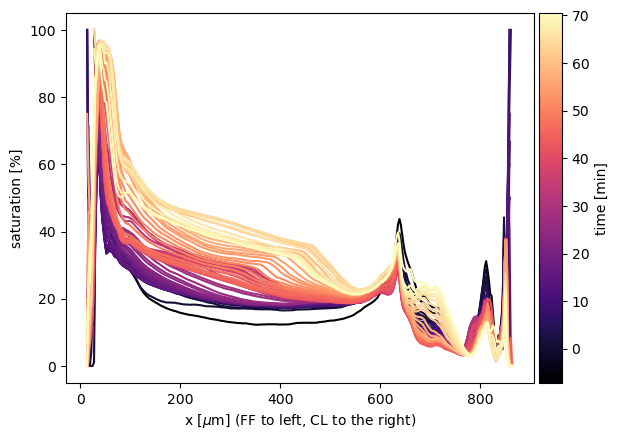

In [63]:
plot_profiles(profdict, timeCT)

In [82]:
roi_dyn_dict = ROI_dynamics(ROIdata, profdict)

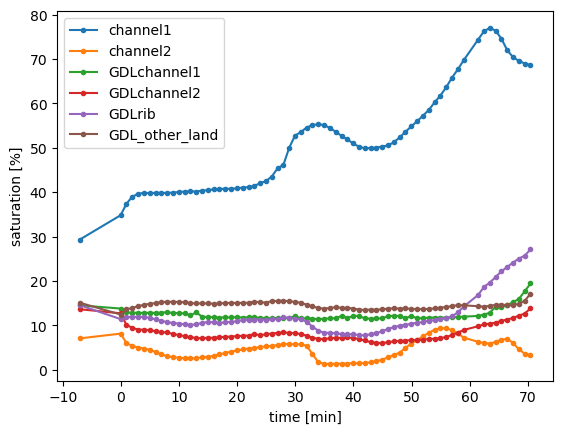

In [46]:
plot_roi_dynamic(roi_dyn_dict, timeCT)

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


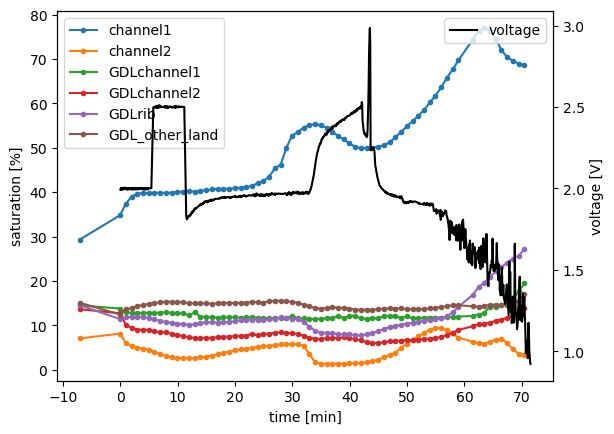

In [78]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage')

channel1
channel2


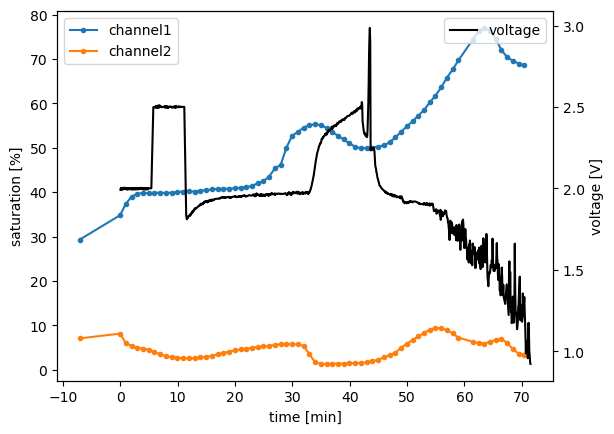

In [80]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage', rois = ['channel1', 'channel2']) #'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land

GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


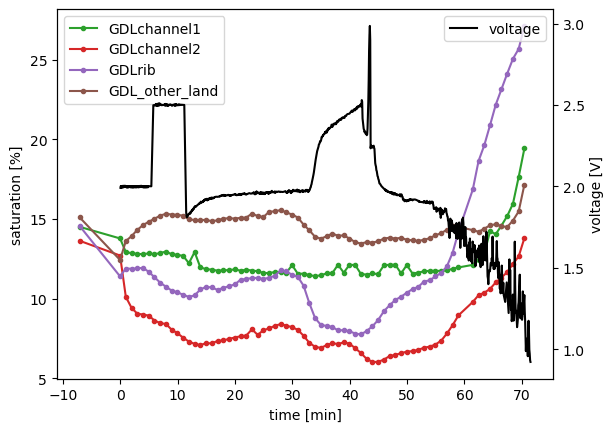

In [81]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage', rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']) #

## Sample 4II

In [82]:
sample = '4II'
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [83]:
seg_data = xr.open_dataset(segpath)
ROIdata  = xr.open_dataset(ROIpath)
if sample == '1':
    t0 = ROIdata['t_utc'][0]
else:
    t0 = charge_dict[sample]['t0']

timeCT = ROIdata['t_utc']-t0
timeEC = charge_dict[sample]['time']

I = -charge_dict[sample]['I']*10 #current density [mA/cm2]
V = -charge_dict[sample]['E'] #voltage


In [84]:
profdict = get_profiles(seg_data, ROIdata )

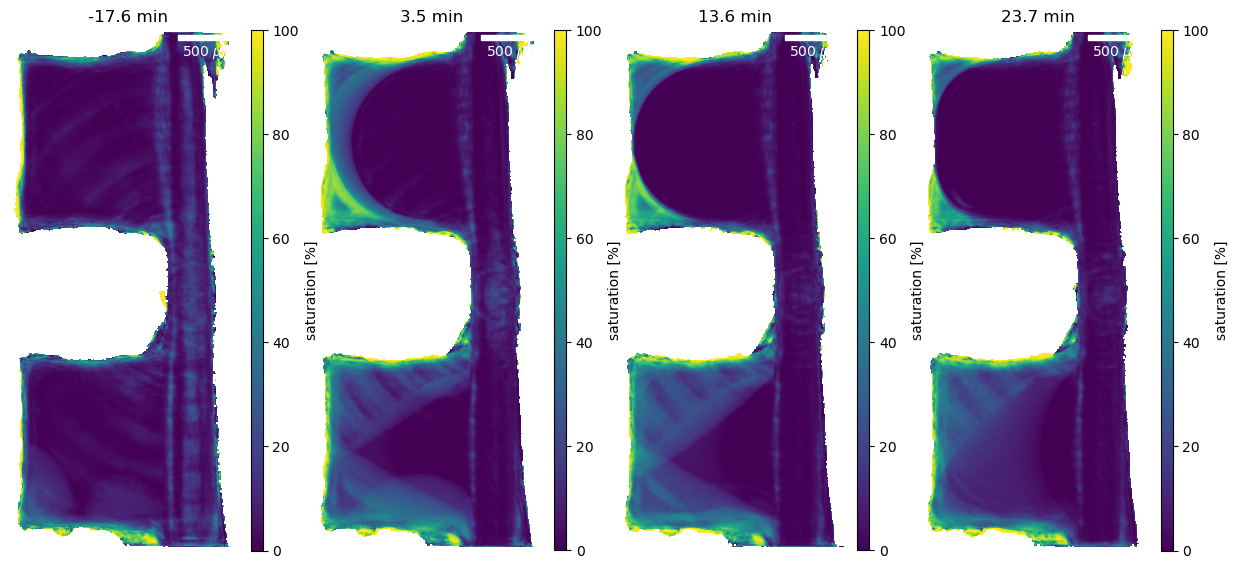

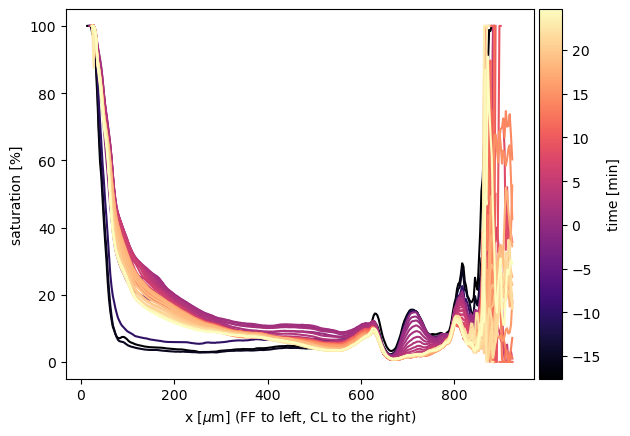

In [86]:
plot_profiles(profdict, timeCT, timesteps = [0,10,30,50])

In [87]:
roi_dyn_dict = ROI_dynamics(ROIdata, profdict)

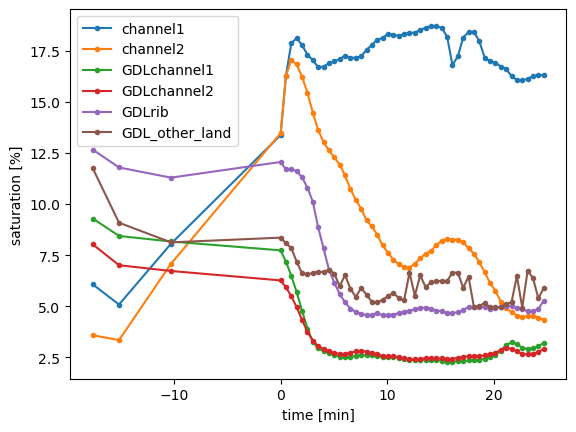

In [88]:
plot_roi_dynamic(roi_dyn_dict, timeCT)

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


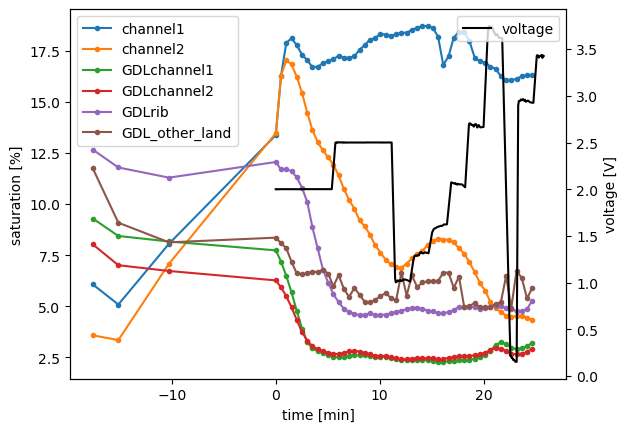

In [89]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage')

channel1
channel2


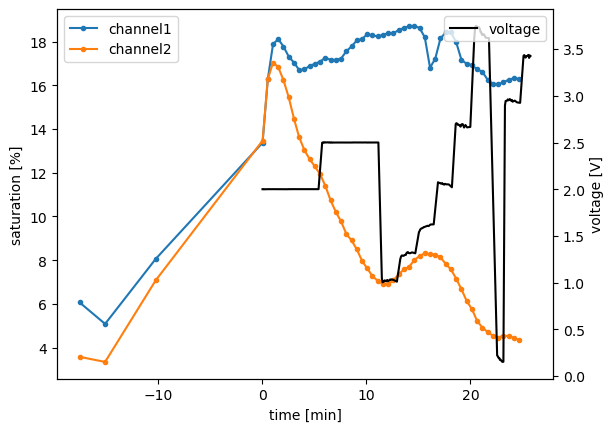

In [90]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage', rois = ['channel1', 'channel2']) #'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land

GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


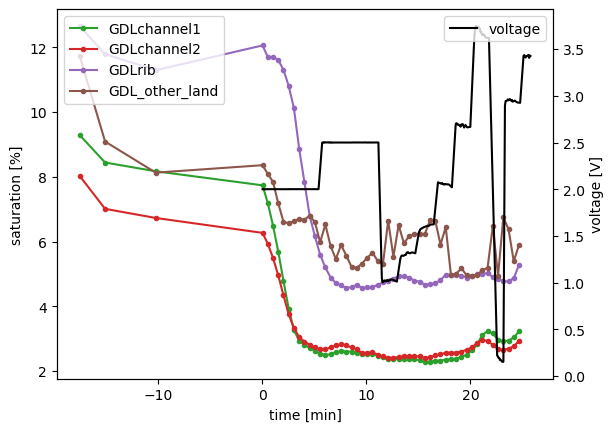

In [91]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage', rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']) #

## Sample 3II

In [4]:
sample = '3II'
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [5]:
seg_data = xr.open_dataset(segpath)
ROIdata  = xr.open_dataset(ROIpath)
if sample == '1':
    t0 = ROIdata['t_utc'][0]
else:
    t0 = charge_dict[sample]['t0']

timeCT = ROIdata['t_utc']-t0
timeEC = charge_dict[sample]['time']

I = -charge_dict[sample]['I']*10 #current density [mA/cm2]
V = -charge_dict[sample]['E'] #voltage


In [6]:
profdict = get_profiles(seg_data, ROIdata )

In [7]:
roi_dyn_dict = ROI_dynamics(ROIdata, profdict)

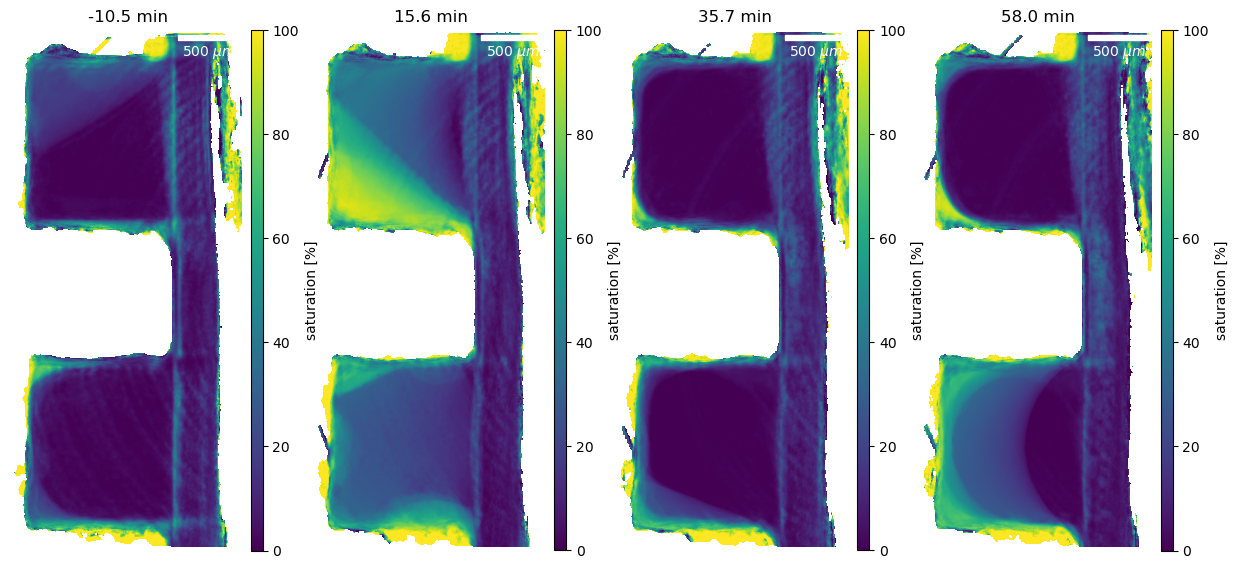

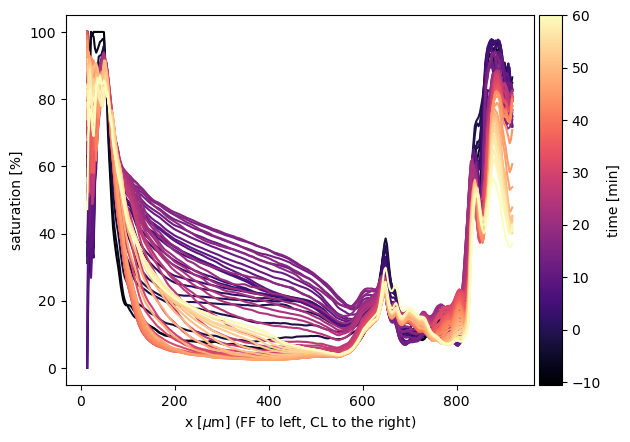

In [8]:
plot_profiles(profdict, timeCT)

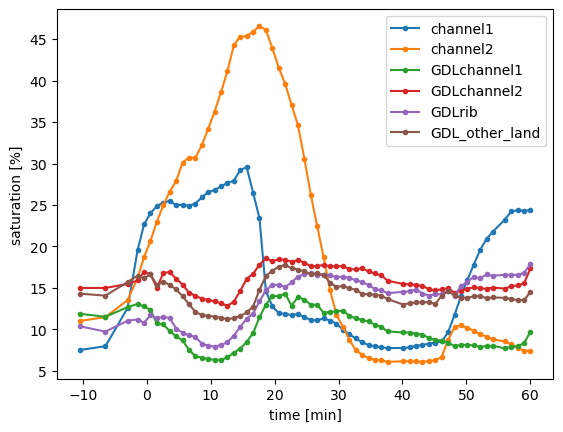

In [9]:
plot_roi_dynamic(roi_dyn_dict, timeCT)

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


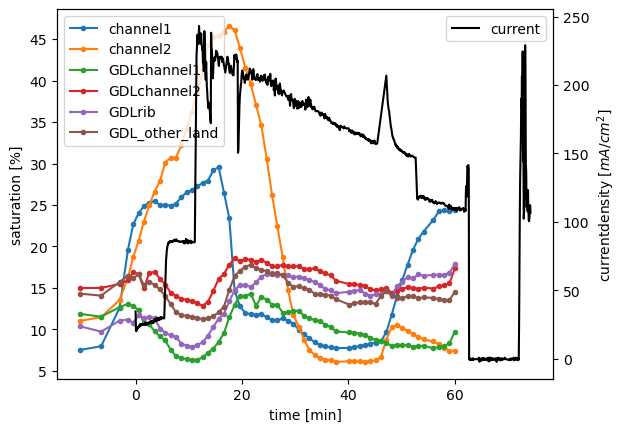

In [10]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current')

channel1
channel2


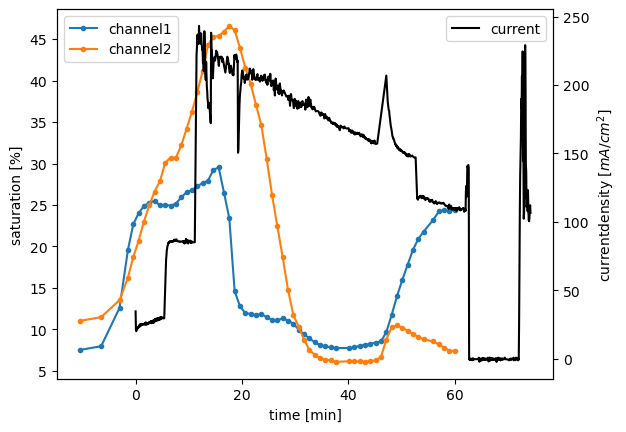

In [11]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current', rois = ['channel1', 'channel2']) #'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land

GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


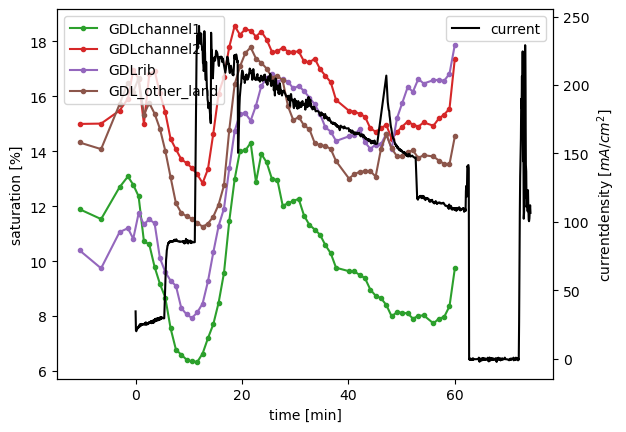

In [12]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current', rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']) #

## Sample 3III

In [13]:
sample = '3III'
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [14]:
seg_data = xr.open_dataset(segpath)
ROIdata  = xr.open_dataset(ROIpath)
if sample == '1':
    t0 = ROIdata['t_utc'][0]
else:
    t0 = charge_dict[sample]['t0']

timeCT = ROIdata['t_utc']-t0
timeEC = charge_dict[sample]['time']

I = -charge_dict[sample]['I']*10 #current density [mA/cm2]
V = -charge_dict[sample]['E'] #voltage


In [15]:
profdict = get_profiles(seg_data, ROIdata )

In [16]:
roi_dyn_dict = ROI_dynamics(ROIdata, profdict)

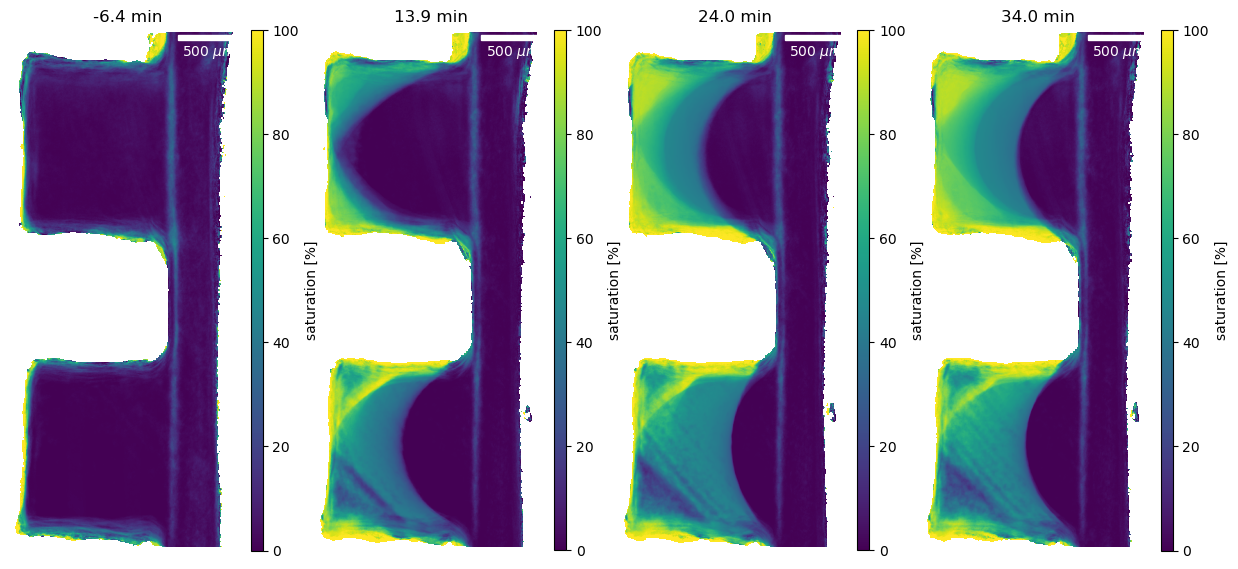

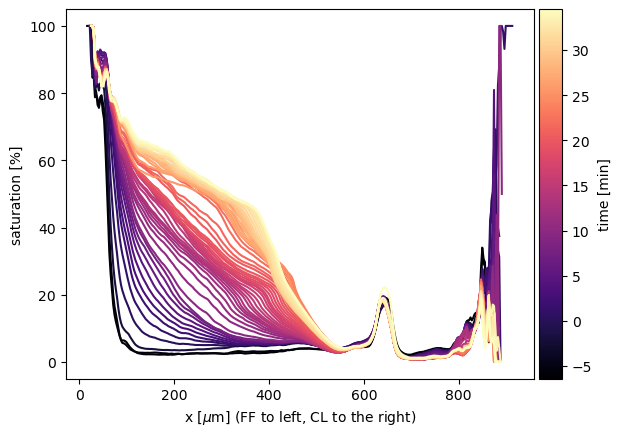

In [17]:
plot_profiles(profdict, timeCT)

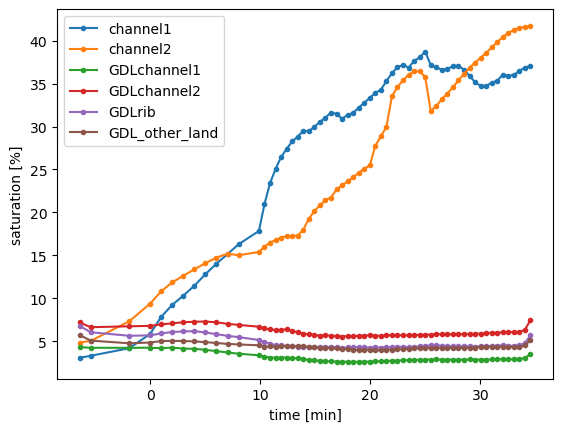

In [18]:
plot_roi_dynamic(roi_dyn_dict, timeCT)

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


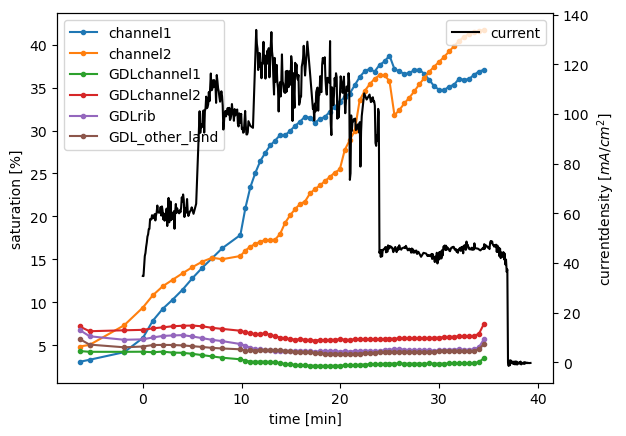

In [19]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current')

channel1
channel2


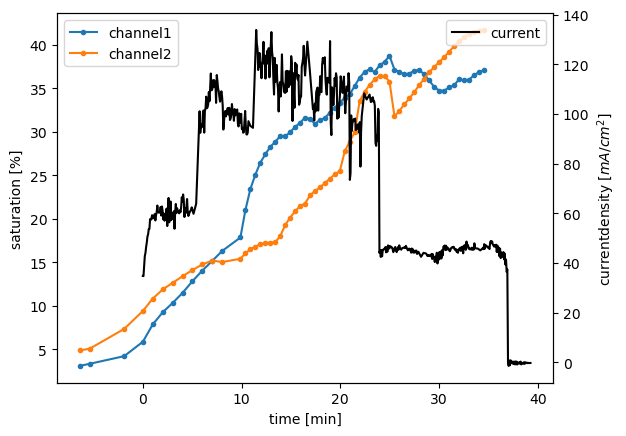

In [20]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current', rois = ['channel1', 'channel2']) #'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land

GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


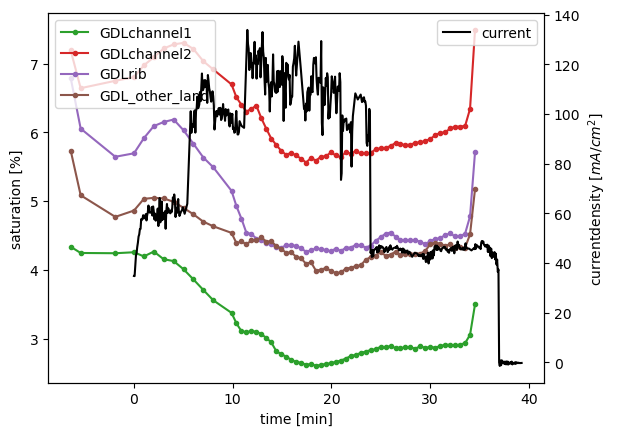

In [21]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current', rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']) #

## Sample 5II

In [6]:
sample = '5II'
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [7]:
seg_data = xr.open_dataset(segpath)
ROIdata  = xr.open_dataset(ROIpath)
if sample == '1':
    t0 = ROIdata['t_utc'][0]
else:
    t0 = charge_dict[sample]['t0']

timeCT = ROIdata['t_utc']-t0
timeEC = charge_dict[sample]['time']

I = -charge_dict[sample]['I']*10 #current density [mA/cm2]
V = -charge_dict[sample]['E'] #voltage


In [8]:
profdict = get_profiles(seg_data, ROIdata )

In [9]:
roi_dyn_dict = ROI_dynamics(ROIdata, profdict)

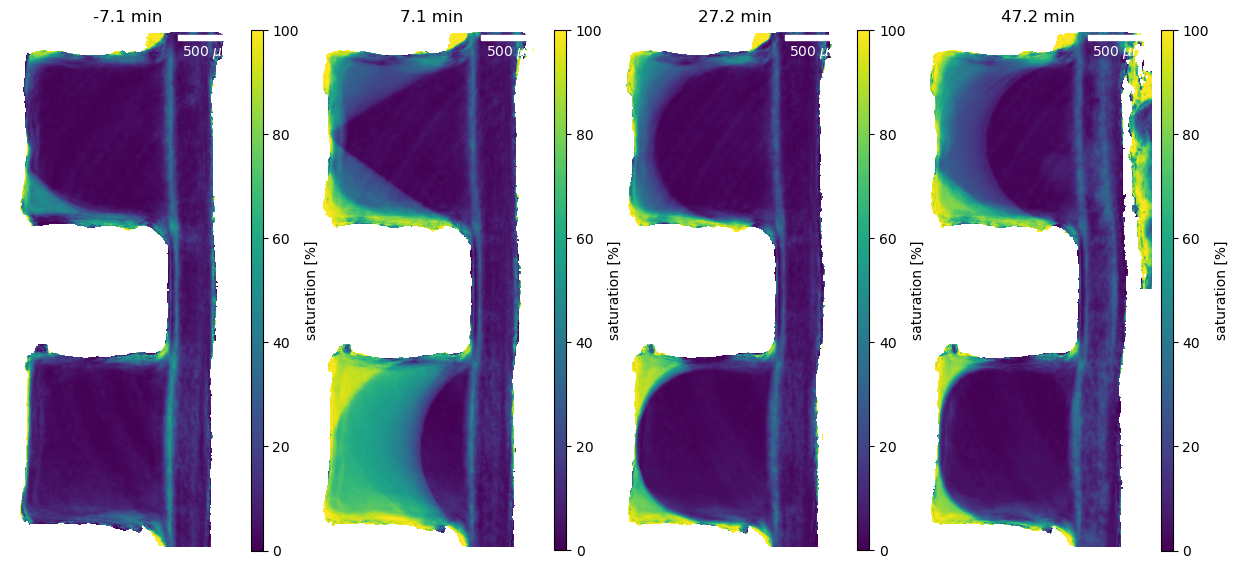

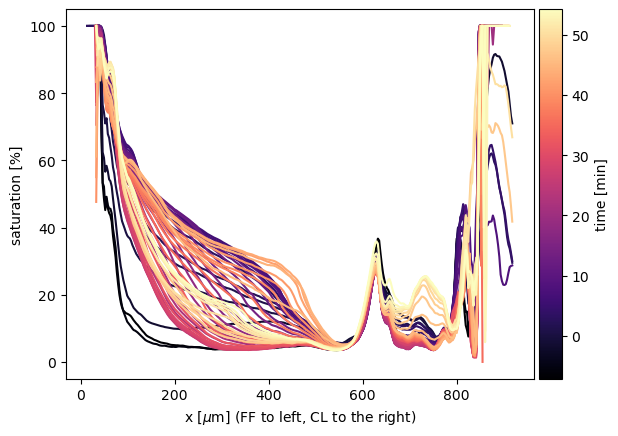

In [10]:
plot_profiles(profdict, timeCT, timesteps = [0,10,30,50])

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


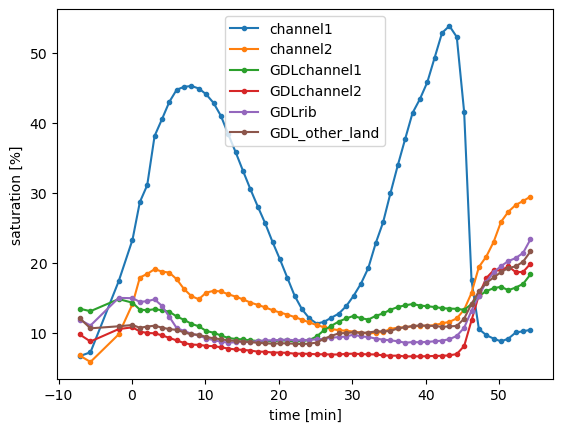

In [11]:
plot_roi_dynamic(roi_dyn_dict, timeCT)

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


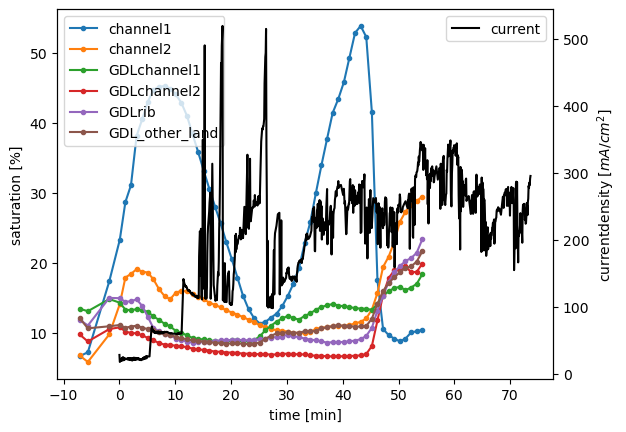

In [12]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current')

channel1
channel2


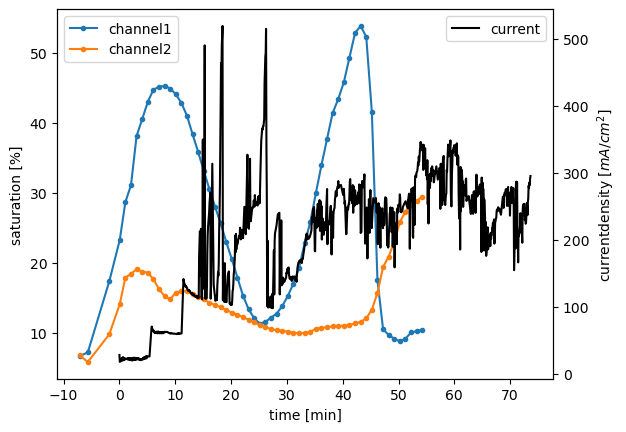

In [13]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current', rois = ['channel1', 'channel2']) #'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land

GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


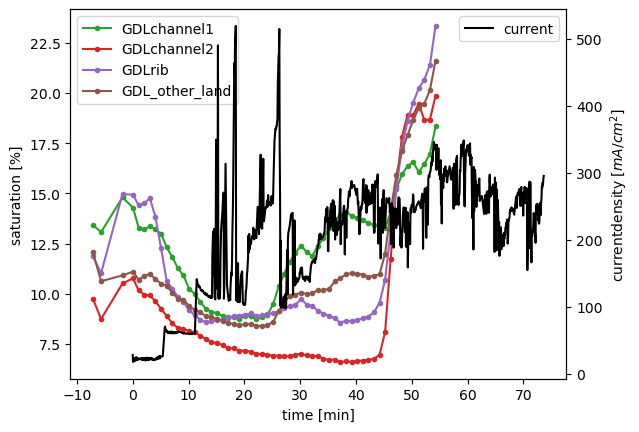

In [14]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'current', rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']) #

## Sample 6

In [38]:
sample = '6'
ROIpath = os.path.join(toppathSSD, '05_water_GDL_ML', sample, sample+'_ROI_segments.nc')
segpath = os.path.join(toppathSSD,'05_water_GDL_ML', sample, sample+'water_segmentation.nc')

In [39]:
seg_data = xr.open_dataset(segpath)
ROIdata  = xr.open_dataset(ROIpath)
if sample == '1':
    t0 = ROIdata['t_utc'][0]
else:
    t0 = charge_dict[sample]['t0']

timeCT = ROIdata['t_utc']-t0
timeEC = charge_dict[sample]['time']

I = -charge_dict[sample]['I']*10 #current density [mA/cm2]
V = -charge_dict[sample]['E'] #voltage


In [40]:
profdict = get_profiles(seg_data, ROIdata )

In [41]:
roi_dyn_dict = ROI_dynamics(ROIdata, profdict)

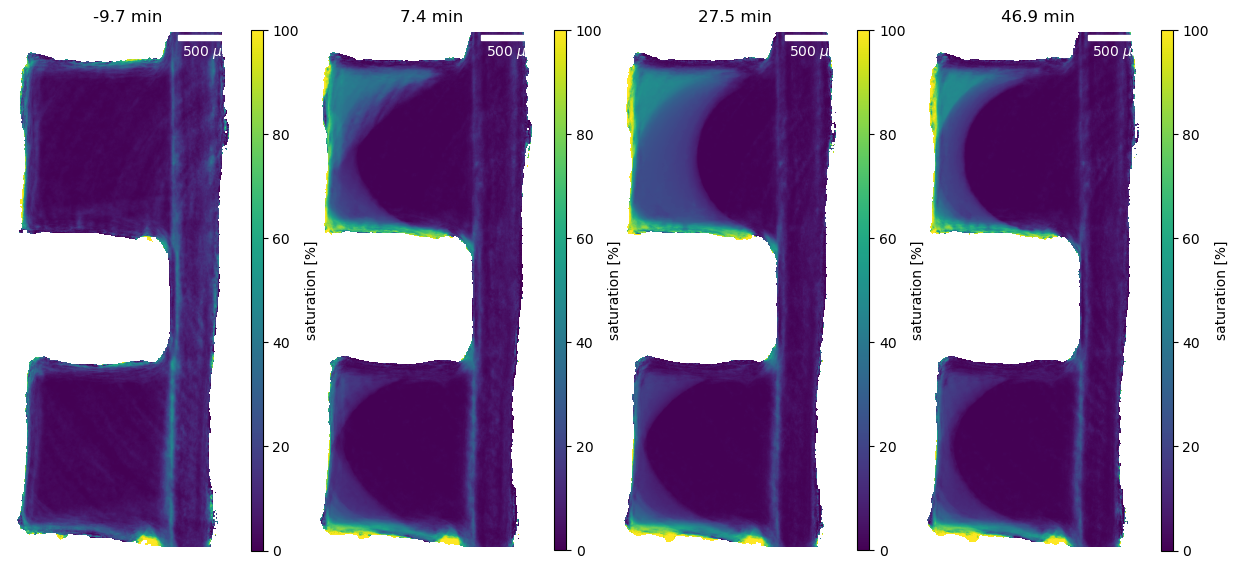

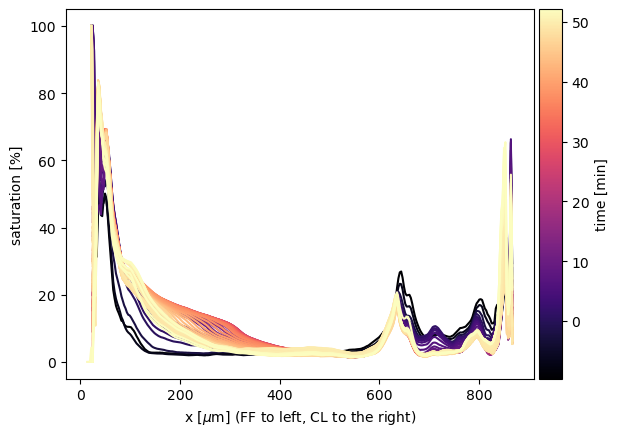

In [42]:
plot_profiles(profdict, timeCT, timesteps = [0,10,30,50])

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


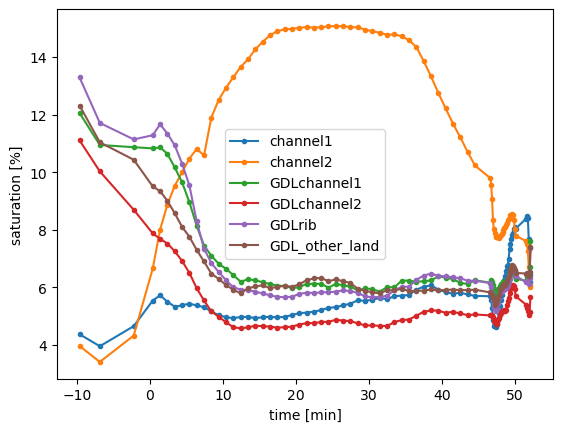

In [43]:
plot_roi_dynamic(roi_dyn_dict, timeCT)

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


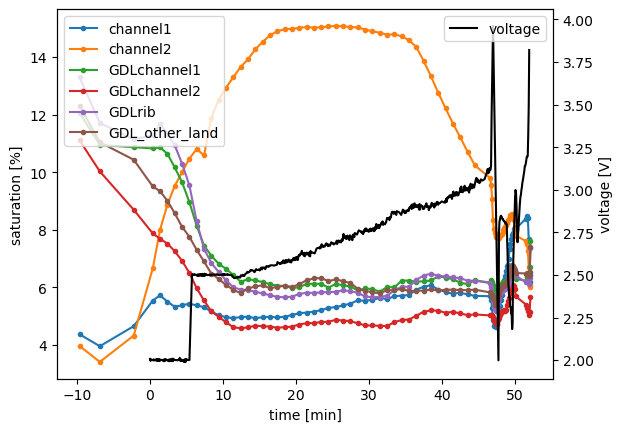

In [47]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage')

channel1
channel2


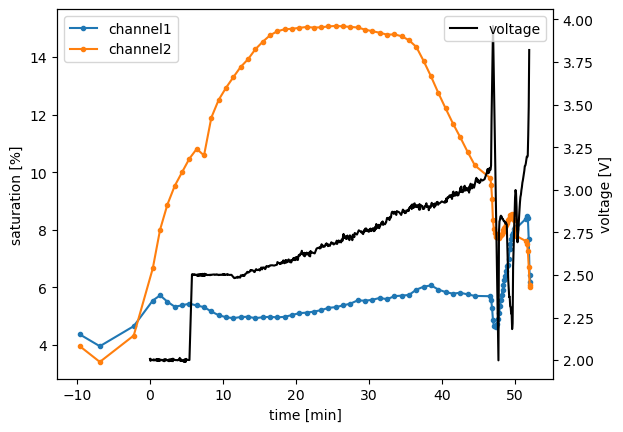

In [48]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage', rois = ['channel1', 'channel2']) #'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land

GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


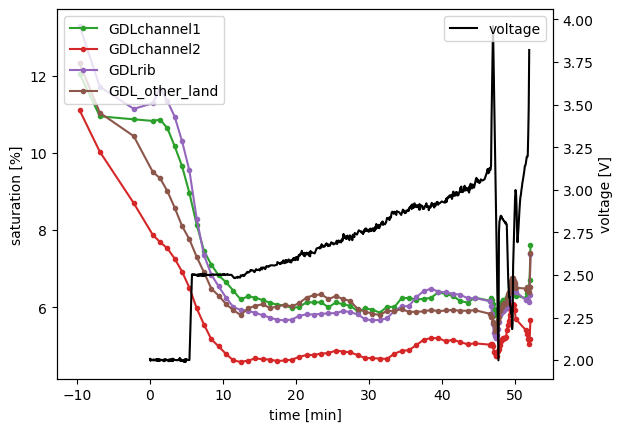

In [49]:
plot_roi_dyn_with_EC(roi_dyn_dict, timeCT, timeEC, I,V, op = 'voltage', rois = ['GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']) #

## paper figures

In [5]:
ROIdata

<xarray.Dataset>
Dimensions:   (x: 750, y: 340, z: 1916, timestep: 71)
Coordinates:
  * x         (x) int64 0 1 2 3 4 5 6 7 8 ... 742 743 744 745 746 747 748 749
  * y         (y) int64 0 1 2 3 4 5 6 7 8 ... 332 333 334 335 336 337 338 339
  * z         (z) int64 0 1 2 3 4 5 6 7 ... 1909 1910 1911 1912 1913 1914 1915
  * timestep  (timestep) int64 0 1 2 3 4 5 6 7 8 ... 62 63 64 65 66 67 68 69 70
Data variables:
    ROI       (x, y, z, timestep) uint8 ...
    GDL       (x, y, z, timestep) uint8 ...
    t_utc     (timestep) float64 1.667e+09 1.667e+09 ... 1.667e+09 1.667e+09
    time      (timestep) float64 ...
Attributes: (12/23)
    name:                                              4
    voxel size:                                        2.75 um
    voxel:                                             2.75e-06
    post rotation cropping coordinates [a:b,c:d,e:f]:  [  30  851   70  768  ...
    rotation angle 1:                                  -4.5
    rotation angle 2:                                  -4.5
    ...                                                ...
    05_ML_cropping:                                    [ 40 790  40 380  50 -50]
    pytrain_git:                                       e42ad75
    05_coely_gitsha:                                   53e8ce2
    GDL_crop:                                          0
    ROI values:                                        [1 2 3 4 5 6]
    ROI:                                               ['channel1', 'channel2...

In [20]:
imROI = ROIdata['ROI'].sel(z = 850, timestep=10)

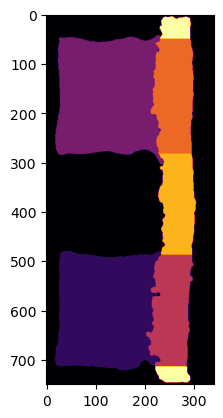

In [44]:
plt.imshow(imROIvirids, cmap='inferno')

In [22]:
imROIvirids = imROI.data.copy()

In [23]:
imROI = imROI.data

In [24]:
np.unique(imROI)

array([0, 1, 2, 3, 4, 5, 6], dtype=uint8)

In [26]:
imROI = np.float16(imROI)

In [27]:
imROI[imROI==0] = np.nan

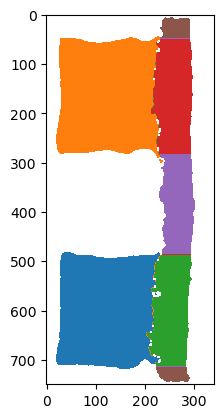

In [39]:
plt.imshow(imROI*2, cmap='tab10', vmin=2, vmax=20)

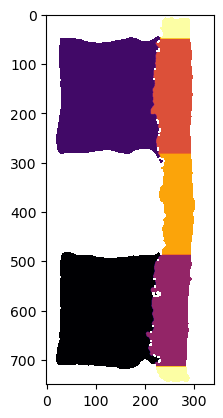

In [45]:
plt.imshow(imROI, cmap='inferno')

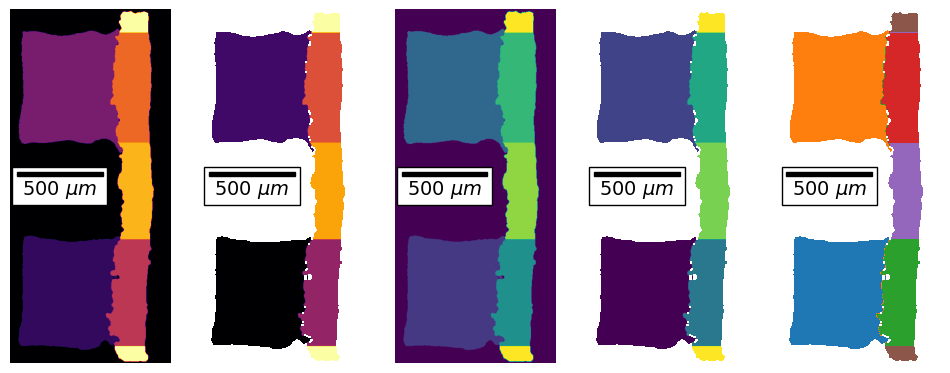

In [95]:
fig, axs = plt.subplots(1,5, figsize=(12,7))
axs[0].imshow(imROIvirids, cmap='inferno', vmin=0, vmax=6)
axs[1].imshow(imROI, cmap='inferno', vmin=1, vmax=6)
axs[2].imshow(imROIvirids, cmap='viridis', vmin=0, vmax=6)
axs[3].imshow(imROI, cmap='viridis', vmin=1, vmax=6)
axs[4].imshow(imROI*2, cmap='tab10', vmin=2, vmax=20)

for ax in axs:
    ax.axis('off')
    scalebar = AnchoredSizeBar(ax.transData,
                           500/2.75, '500 $\mu m$', 'center left', 
                           pad=0.25,
                           color='black',
                           frameon=True,
                           size_vertical=8,
                           fontproperties=fm.FontProperties(size=14))
    ax.add_artist(scalebar)

In [74]:
norm1 = Normalize(vmin=0, vmax=6)
norm2 = Normalize(vmin=1, vmax=6)

In [73]:
allrois = ['channel1', 'channel2', 'GDLchannel1', 'GDLchannel2', 'GDLrib', 'GDL_other_land']

In [79]:
special_colors = {'viridis': [cm.viridis(norm1(i)) for i in range(1,7)],
                 'inferno': [cm.inferno(norm1(i)) for i in range(1,7)],
                  'viridis_nan': [cm.viridis(norm2(i)) for i in range(1,7)],
                  'inferno_nan': [cm.inferno(norm2(i)) for i in range(1,7)]                 
                 }

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


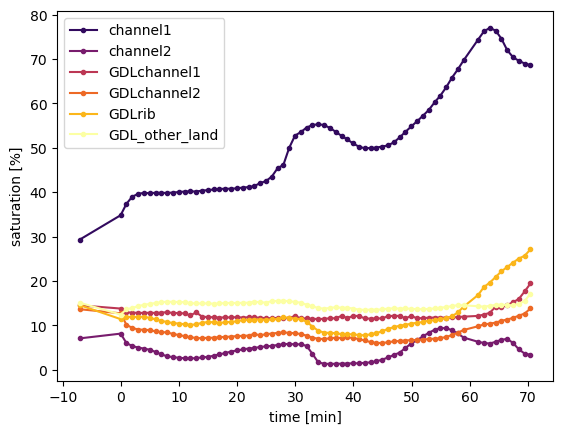

In [84]:
plot_roi_dynamic(roi_dyn_dict, timeCT, colors=special_colors['inferno'])

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


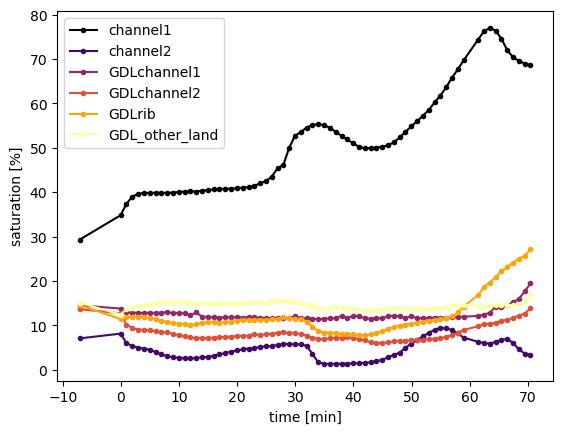

In [85]:
plot_roi_dynamic(roi_dyn_dict, timeCT, colors=special_colors['inferno_nan'])

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


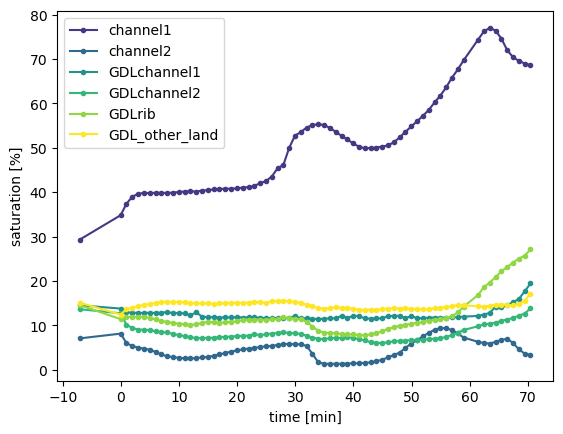

In [86]:
plot_roi_dynamic(roi_dyn_dict, timeCT, colors=special_colors['viridis'])

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


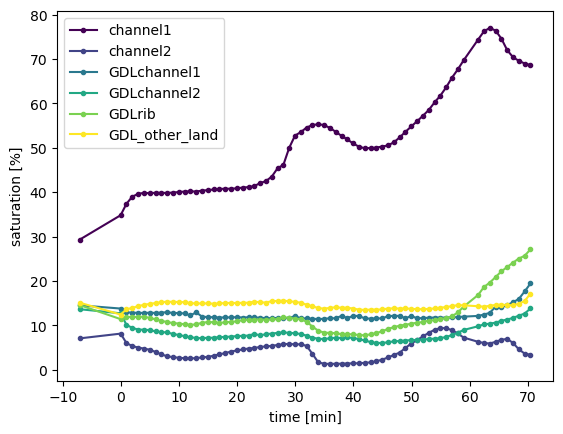

In [87]:
plot_roi_dynamic(roi_dyn_dict, timeCT, colors=special_colors['viridis_nan'])

channel1
channel2
GDLchannel1
GDLchannel2
GDLrib
GDL_other_land


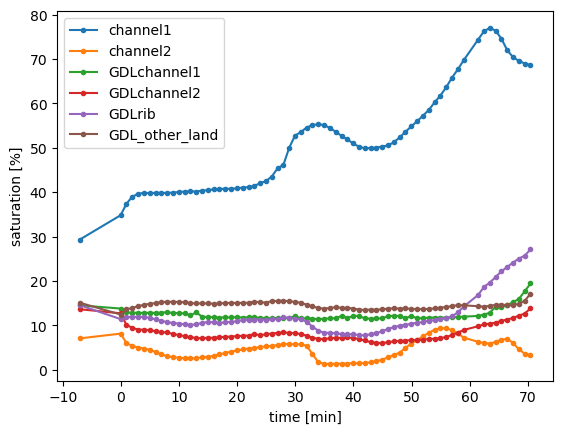

In [88]:
plot_roi_dynamic(roi_dyn_dict, timeCT)